In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/simuation_results2.csv")
df.head()

,sim,model_knowledge,w,perf
0,0,0.0,0.00,0.296875
1,0,0.0,0.01,0.324219
2,0,0.0,0.02,0.437500
3,0,0.0,0.03,0.328125
4,0,0.0,0.04,0.347656


In [5]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf"]
      .mean()
      .assign(
          model_knowledge=lambda d: ((d["model_knowledge"] - 0.5) / 0.5).round(2),
          w=lambda d: d["w"].round(2)
      )
)
df_plot.head()

,model_knowledge,w,perf
0,-1.0,0.00,0.173691
1,-1.0,0.01,0.152480
2,-1.0,0.02,0.145645
3,-1.0,0.03,0.151855
4,-1.0,0.04,0.129863


In [6]:
matrix = df_plot.pivot(index="model_knowledge", columns="w", values="perf")
matrix.head()

w,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.00
model_knowledge,,,,,,,,,,,,,,,,,,,,,
-1.00,0.173691,0.152480,0.145645,0.151855,0.129863,0.138262,0.115371,0.108965,0.110566,0.109082,...,-0.475801,-0.510957,-0.497676,-0.483184,-0.474199,-0.479043,-0.468418,-0.509277,-0.491426,-0.490566
-0.98,0.168887,0.158574,0.145254,0.152480,0.148301,0.130449,0.115410,0.112715,0.109355,0.104824,...,-0.502793,-0.476934,-0.496738,-0.477246,-0.483184,-0.488340,-0.500137,-0.488379,-0.476777,-0.483457
-0.96,0.152324,0.155332,0.133145,0.154746,0.153770,0.109785,0.114746,0.095684,0.136426,0.084004,...,-0.491543,-0.473848,-0.480254,-0.479512,-0.487012,-0.490020,-0.499316,-0.494785,-0.503887,-0.497598
-0.94,0.188574,0.170645,0.165684,0.145996,0.142559,0.142598,0.112402,0.112949,0.099434,0.068066,...,-0.497051,-0.473730,-0.482949,-0.483652,-0.502324,-0.489473,-0.476426,-0.499395,-0.484785,-0.489434
-0.92,0.169121,0.148418,0.139980,0.142012,0.138809,0.141777,0.111387,0.109629,0.108379,0.079980,...,-0.491152,-0.483301,-0.493887,-0.504160,-0.452520,-0.492949,-0.473418,-0.484785,-0.489473,-0.482949


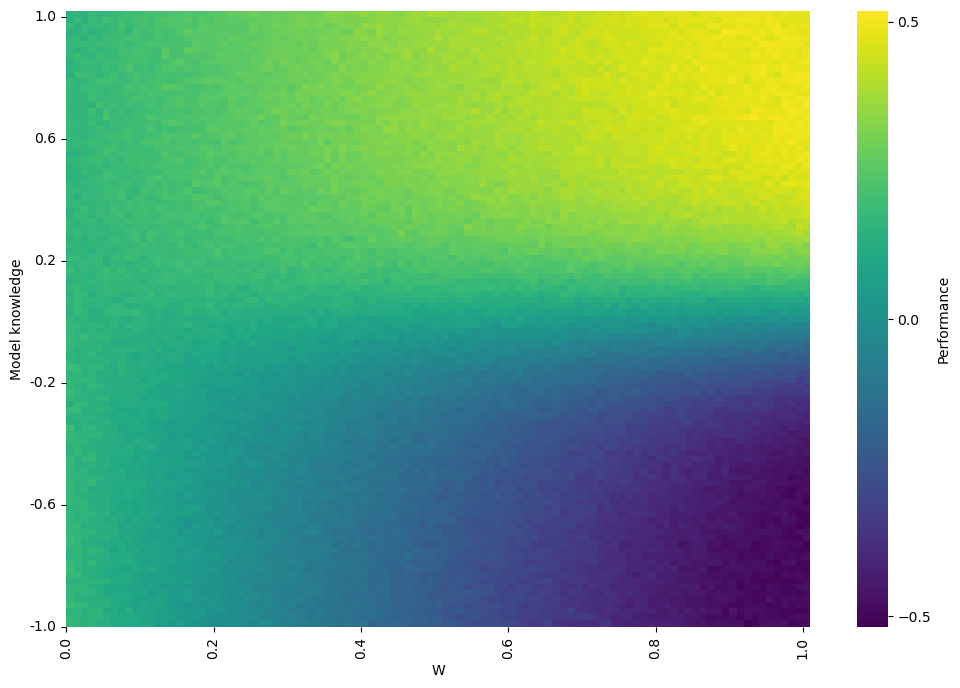

In [7]:
plt.figure(figsize=(12, 8))

sns.heatmap(matrix, cmap="viridis", annot=False, cbar_kws={"label": "Performance", "ticks": [-0.5, 0.0, 0.5]})

# plt.contour(matrix.values, levels=[0], colors="black", linewidths=1)
# plt.axhline(y=50, color="red", linestyle="--", linewidth=2)

plt.gca().invert_yaxis()
plt.ylabel("Model knowledge")
plt.xlabel("W")

# Use the actual index and columns
plt.yticks(
    np.arange(0, len(matrix.index), 20),   # positions
    matrix.index[::20]                     # labels
)
plt.xticks(
    np.arange(0, len(matrix.columns), 20),  # positions
    matrix.columns[::20]                    # labels
)

plt.show()
